# IBM HR Attrition — Multivariate Analysis

This notebook explores relationships between multiple employee characteristics to identify patterns associated with employee attrition.

The analysis uses the cleaned dataset created in the data-preparation notebook and focuses on correlations, pairwise relationships, and interactions between key attrition factors.

## 1. Imports

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

## 2. Loading the Processed Dataset

In [74]:
df = pd.read_csv("../data/processed/cleaned_hr_data.csv")

In [75]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeGroup,TenureGroup,YearsInCurrentRoleGroup,IncomeGroup
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,0,1,6,4,0,5,36–45,Established (6–10),3–5 years,5000–7999
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,3,3,10,7,1,7,46–55,Established (6–10),6–10 years,5000–7999
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,3,0,0,0,0,36–45,New Employees (0–2),0–2 years,Under 3000
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,8,7,3,0,26–35,Established (6–10),6–10 years,Under 3000
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,3,2,2,2,2,26–35,New Employees (0–2),0–2 years,3000–4999


In [76]:
df.shape

(1470, 36)

## 3. Correlation Analysis

In [77]:
correlation_df = df.drop(
    columns=[
        "Attrition",
        "EmployeeNumber",
        "AgeGroup",
        "TenureGroup",
        "YearsInCurrentRoleGroup",
        "IncomeGroup",
    ],
    errors="ignore"
)

correlation_df = pd.get_dummies(
    correlation_df,
    drop_first=True,
    dtype=int
)

correlation_df["AttritionBinary"] = df["Attrition"].map({
    "No": 0,
    "Yes": 1,
})

In [78]:
correlation_df.head()

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes,AttritionBinary
0,41,1102,1,2,2,94,3,2,4,5993,...,0,0,0,0,1,0,0,1,1,1
1,49,279,8,1,3,61,2,2,2,5130,...,0,0,0,1,0,0,1,0,0,0
2,37,1373,2,2,4,92,2,1,3,2090,...,0,0,0,0,0,0,0,1,1,1
3,33,1392,3,4,4,56,3,1,3,2909,...,0,0,0,1,0,0,1,0,1,0
4,27,591,2,1,1,40,3,1,2,3468,...,0,0,0,0,0,0,1,0,0,0


In [79]:
correlation_matrix = correlation_df.corr()

In [80]:
attrition_correlations = (
    correlation_matrix["AttritionBinary"]
    .drop("AttritionBinary")
    .sort_values(
        key=lambda values: values.abs(),
        ascending=False,
    )
)

display(attrition_correlations.head(15).round(2))

OverTime_Yes                        0.25
MaritalStatus_Single                0.18
TotalWorkingYears                  -0.17
JobLevel                           -0.17
YearsInCurrentRole                 -0.16
MonthlyIncome                      -0.16
Age                                -0.16
JobRole_Sales Representative        0.16
YearsWithCurrManager               -0.16
StockOptionLevel                   -0.14
YearsAtCompany                     -0.13
JobInvolvement                     -0.13
BusinessTravel_Travel_Frequently    0.12
JobSatisfaction                    -0.10
EnvironmentSatisfaction            -0.10
Name: AttritionBinary, dtype: float64

In [81]:
top_attrition_features = attrition_correlations.head(15).index

heatmap_columns = list(top_attrition_features) + ["AttritionBinary"]

top_attrition_correlation_matrix = correlation_matrix.loc[
    heatmap_columns,
    heatmap_columns,
]

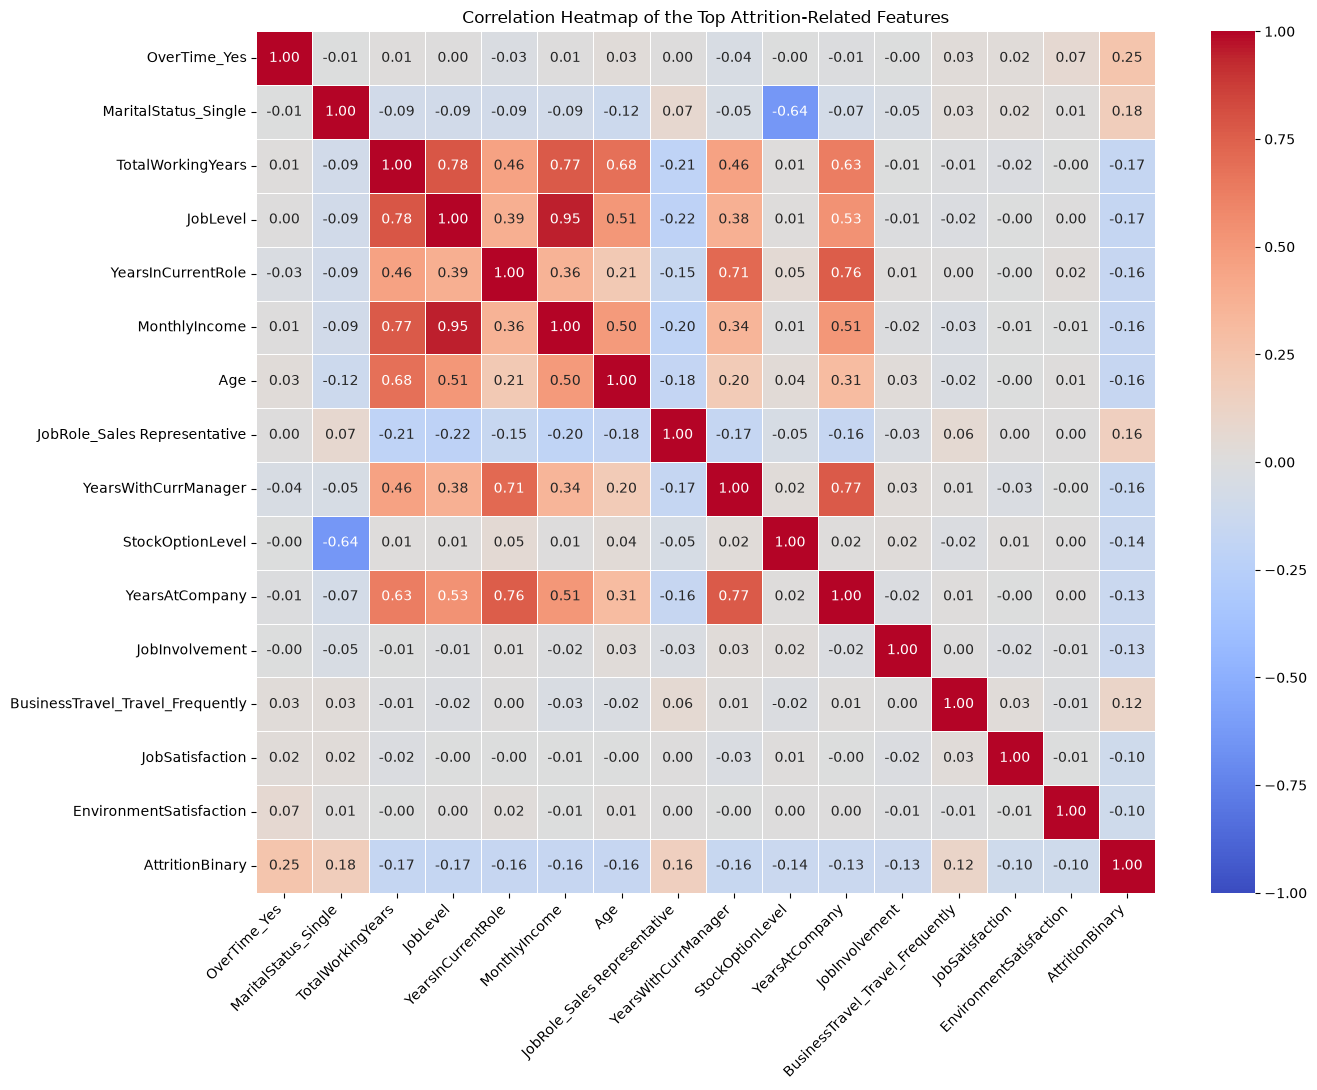

In [82]:
plt.figure(figsize=(14, 11))

sns.heatmap(
    top_attrition_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)

plt.title("Correlation Heatmap of the Top Attrition-Related Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Observation:** No individual feature shows a strong correlation with attrition, suggesting that employee turnover is influenced by a combination of factors rather than one dominant cause. Overtime and being single show the strongest positive relationships with attrition. Conversely, higher job level, monthly income, total working years, and years with the current manager are associated with lower attrition. These correlations indicate relationships within the sample but do not establish causation.

### 3.1 Numerical Feature Correlations

In [83]:
numerical_features = (
    df.select_dtypes(include="number")
    .drop(
        columns=["EmployeeNumber"],
        errors="ignore",
    )
)

numerical_correlation_matrix = numerical_features.corr().round(2)

In [84]:
display(numerical_correlation_matrix)

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.00,0.01,-0.00,0.21,0.01,0.02,0.03,0.51,-0.00,0.50,...,0.00,0.05,0.04,0.68,-0.02,-0.02,0.31,0.21,0.22,0.20
DailyRate,0.01,1.00,-0.00,-0.02,0.02,0.02,0.05,0.00,0.03,0.01,...,0.00,0.01,0.04,0.01,0.00,-0.04,-0.03,0.01,-0.03,-0.03
DistanceFromHome,-0.00,-0.00,1.00,0.02,-0.02,0.03,0.01,0.01,-0.00,-0.02,...,0.03,0.01,0.04,0.00,-0.04,-0.03,0.01,0.02,0.01,0.01
Education,0.21,-0.02,0.02,1.00,-0.03,0.02,0.04,0.10,-0.01,0.09,...,-0.02,-0.01,0.02,0.15,-0.03,0.01,0.07,0.06,0.05,0.07
EnvironmentSatisfaction,0.01,0.02,-0.02,-0.03,1.00,-0.05,-0.01,0.00,-0.01,-0.01,...,-0.03,0.01,0.00,-0.00,-0.02,0.03,0.00,0.02,0.02,-0.00
HourlyRate,0.02,0.02,0.03,0.02,-0.05,1.00,0.04,-0.03,-0.07,-0.02,...,-0.00,0.00,0.05,-0.00,-0.01,-0.00,-0.02,-0.02,-0.03,-0.02
JobInvolvement,0.03,0.05,0.01,0.04,-0.01,0.04,1.00,-0.01,-0.02,-0.02,...,-0.03,0.03,0.02,-0.01,-0.02,-0.01,-0.02,0.01,-0.02,0.03
JobLevel,0.51,0.00,0.01,0.10,0.00,-0.03,-0.01,1.00,-0.00,0.95,...,-0.02,0.02,0.01,0.78,-0.02,0.04,0.53,0.39,0.35,0.38
JobSatisfaction,-0.00,0.03,-0.00,-0.01,-0.01,-0.07,-0.02,-0.00,1.00,-0.01,...,0.00,-0.01,0.01,-0.02,-0.01,-0.02,-0.00,-0.00,-0.02,-0.03
MonthlyIncome,0.50,0.01,-0.02,0.09,-0.01,-0.02,-0.02,0.95,-0.01,1.00,...,-0.02,0.03,0.01,0.77,-0.02,0.03,0.51,0.36,0.34,0.34


In [85]:
upper_triangle = numerical_correlation_matrix.where(
    np.triu(
        np.ones(numerical_correlation_matrix.shape),
        k=1,
    ).astype(bool)
)

In [86]:
strong_numerical_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

strong_numerical_correlations.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation",
]

strong_numerical_correlations = (
    strong_numerical_correlations[
        strong_numerical_correlations["Correlation"].abs() >= 0.5
    ]
    .sort_values(
        by="Correlation",
        key=lambda values: values.abs(),
        ascending=False,
    )
    .reset_index(drop=True)
)

display(strong_numerical_correlations)

,Feature 1,Feature 2,Correlation
0,JobLevel,MonthlyIncome,0.95
1,JobLevel,TotalWorkingYears,0.78
2,MonthlyIncome,TotalWorkingYears,0.77
3,PercentSalaryHike,PerformanceRating,0.77
4,YearsAtCompany,YearsWithCurrManager,0.77
5,YearsAtCompany,YearsInCurrentRole,0.76
6,YearsInCurrentRole,YearsWithCurrManager,0.71
7,Age,TotalWorkingYears,0.68
8,TotalWorkingYears,YearsAtCompany,0.63
9,YearsAtCompany,YearsSinceLastPromotion,0.62


In [87]:
strong_numerical_features = pd.unique(
    strong_numerical_correlations[
        ["Feature 1", "Feature 2"]
    ].values.ravel()
)

strong_numerical_matrix = (
    df[strong_numerical_features]
    .corr()
    .round(2)
)

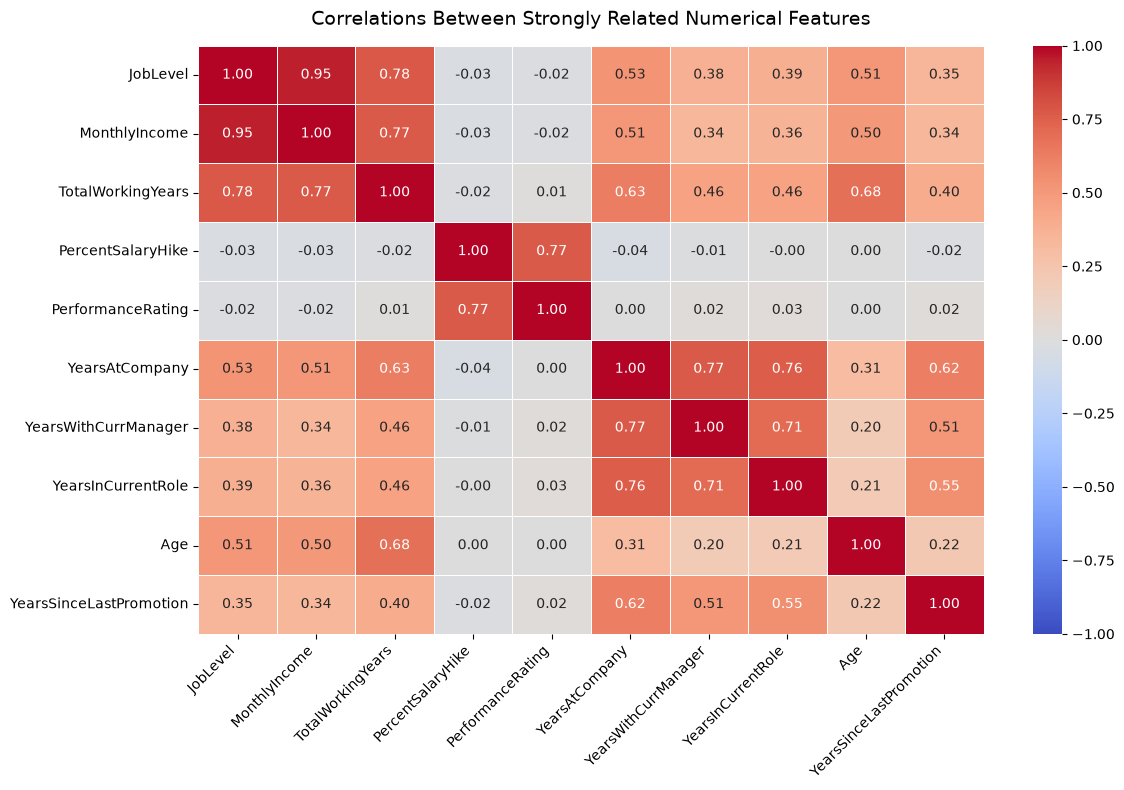

In [88]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    strong_numerical_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)

plt.title(
    "Correlations Between Strongly Related Numerical Features",
    fontsize=14,
    pad=15,
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Observation:** The strongest numerical relationship appears between job level and monthly income, indicating that employees in higher-level positions generally earn more. Age and total working years are also strongly related, while company-tenure measures—such as years at the company, in the current role, and with the current manager—are closely connected. Performance rating is strongly associated with percentage salary increases. Overall, these relationships mainly reflect expected career progression and overlapping tenure measures rather than direct drivers of employee attrition.

### 3.2 Numerical Feature Correlations with Attrition

In [89]:
attrition_numerical_correlations = (
    numerical_features
    .corrwith(correlation_df["AttritionBinary"])
    .dropna()
    .sort_values(ascending=False)
    .round(2)
)

display(
    attrition_numerical_correlations.to_frame(
        name="Correlation with Attrition"
    )
)

,Correlation with Attrition
DistanceFromHome,0.08
NumCompaniesWorked,0.04
MonthlyRate,0.02
PerformanceRating,0.00
HourlyRate,-0.01
PercentSalaryHike,-0.01
Education,-0.03
YearsSinceLastPromotion,-0.03
RelationshipSatisfaction,-0.05
DailyRate,-0.06


In [90]:
attrition_numerical_heatmap = (
    attrition_numerical_correlations
    .to_frame(name="Attrition")
)

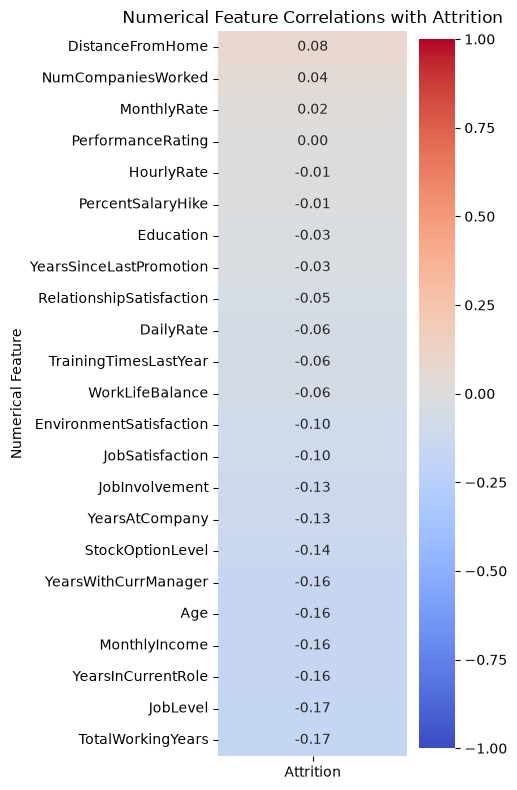

In [91]:
plt.figure(figsize=(5, 8))

sns.heatmap(
    attrition_numerical_heatmap,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Numerical Feature Correlations with Attrition")
plt.ylabel("Numerical Feature")

plt.tight_layout()
plt.show()

**Observation:** The numerical correlations are predominantly weak and negative. Attrition tends to decrease as employee experience, seniority, income, and company tenure increase. Distance from home and the number of previously worked companies show small positive relationships, but their low correlation values indicate limited explanatory power when considered independently.

### 3.3 Categorical Feature Correlations with Attrition

In [92]:
derived_group_columns = [
    "AgeGroup",
    "TenureGroup",
    "YearsInCurrentRoleGroup",
    "IncomeGroup",
]

categorical_features = (
    df.select_dtypes(
        include=["object", "category", "string"]
    )
    .drop(
        columns=[
            "Attrition",
            *derived_group_columns,
        ],
        errors="ignore",
    )
)

categorical_features.columns.tolist()

['BusinessTravel',
 'Department',
 'EducationField',
 'Gender',
 'JobRole',
 'MaritalStatus',
 'OverTime']

In [93]:
encoded_categorical_features = pd.get_dummies(
    categorical_features,
    drop_first=False,
    dtype=int,
)

categorical_attrition_correlations = (
    encoded_categorical_features
    .corrwith(correlation_df["AttritionBinary"])
    .sort_values(ascending=False)
    .round(2)
)

In [94]:
categorical_correlation_table = (
    categorical_attrition_correlations
    .rename("Correlation with Attrition")
    .reset_index()
    .rename(
        columns={
            "index": "Category",
        }
    )
)

display(categorical_correlation_table)

,Category,Correlation with Attrition
0,OverTime_Yes,0.25
1,MaritalStatus_Single,0.18
2,JobRole_Sales Representative,0.16
3,BusinessTravel_Travel_Frequently,0.12
4,JobRole_Laboratory Technician,0.10
5,Department_Sales,0.08
6,EducationField_Technical Degree,0.07
7,EducationField_Marketing,0.06
8,EducationField_Human Resources,0.04
9,JobRole_Human Resources,0.04


In [95]:
categorical_attrition_heatmap = (
    categorical_attrition_correlations
    .to_frame(name="Attrition")
)

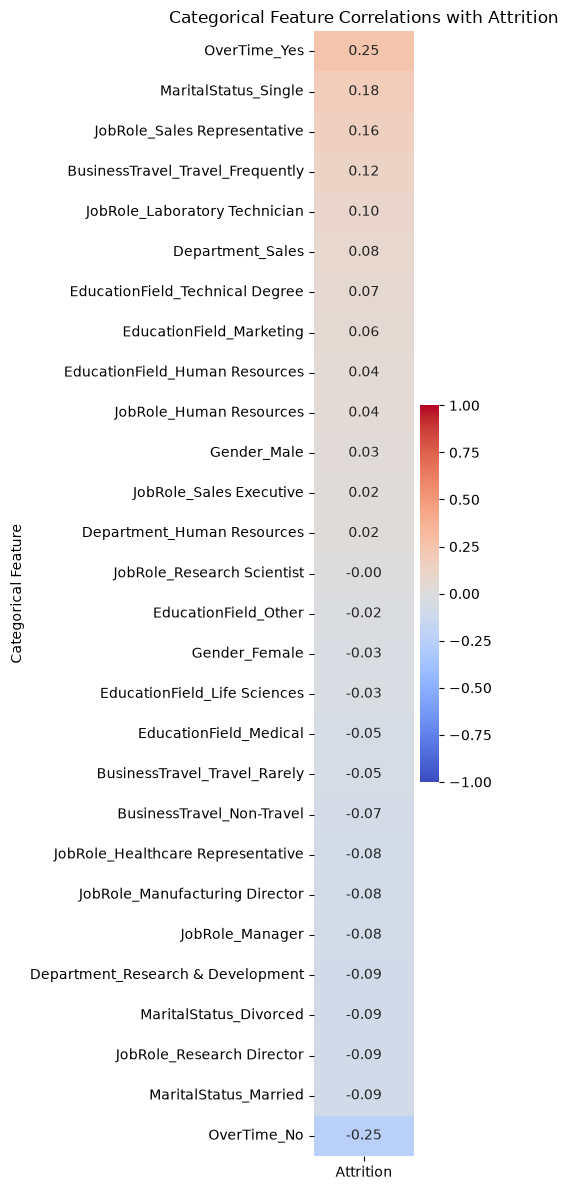

In [96]:
plt.figure(figsize=(5, 12))

sns.heatmap(
    categorical_attrition_heatmap,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Categorical Feature Correlations with Attrition")
plt.ylabel("Categorical Feature")

plt.tight_layout()
plt.show()

**Observation:** Overtime shows the clearest categorical relationship with attrition: employees working overtime are more likely to leave, while those without overtime are more likely to remain. Single employees and those who travel frequently for business also show higher attrition. In contrast, married employees, employees who rarely or never travel, and several senior job roles are associated with lower attrition. Although these relationships are stronger than most numerical correlations, none is strong enough to explain employee turnover independently.

## 4. Pairwise Feature Exploration

### 4.1 Overtime × Job Satisfaction

In [97]:
no_overtime_satisfaction = (
    overtime_satisfaction[
        overtime_satisfaction["OverTime"] == "No"
    ]
    .drop(columns="OverTime")
    .reset_index(drop=True)
)

overtime_satisfaction_table = (
    overtime_satisfaction[
        overtime_satisfaction["OverTime"] == "Yes"
    ]
    .drop(columns="OverTime")
    .reset_index(drop=True)
)

In [98]:
overtime_satisfaction_comparison = pd.concat(
    {
        "Without Overtime": no_overtime_satisfaction,
        "With Overtime": overtime_satisfaction_table,
    },
    axis=1,
)

display(overtime_satisfaction_comparison)

Without Overtime                                         With Overtime  \
   JobSatisfaction Employees EmployeesLeft AttritionRate JobSatisfaction   
0                1       205            36         17.56               1   
1                2       211            20          9.48               2   
2                3       321            32          9.97               3   
3                4       317            22          6.94               4   

                                         
  Employees EmployeesLeft AttritionRate  
0        84            30         35.71  
1        69            26         37.68  
2       121            41         33.88  
3       142            30         21.13

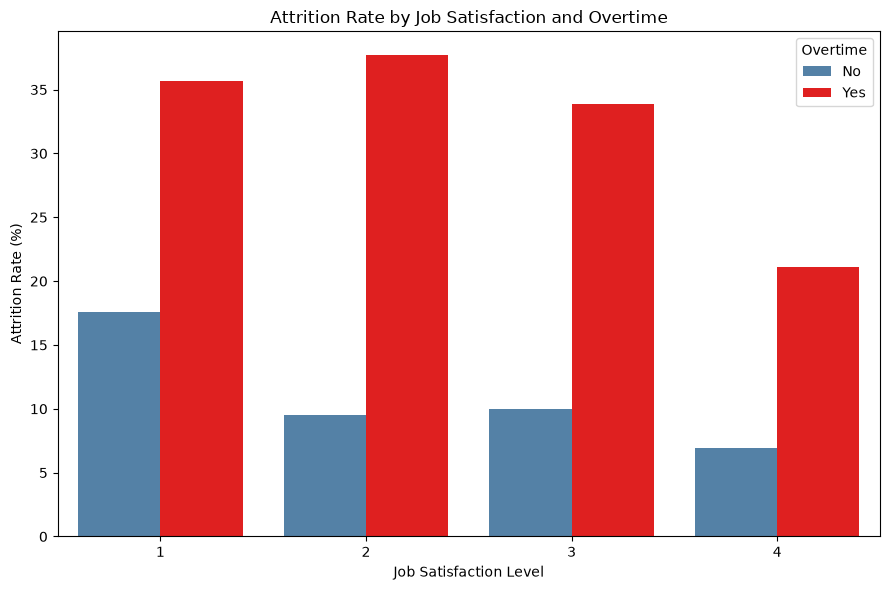

In [99]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=overtime_satisfaction,
    x="JobSatisfaction",
    y="AttritionRate",
    hue="OverTime",
    palette={
        "No": "steelblue",
        "Yes": "red",
    },
)

plt.title("Attrition Rate by Job Satisfaction and Overtime")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")
plt.legend(title="Overtime")

plt.tight_layout()
plt.show()

**Observation:** Employees working overtime show substantially higher attrition rates across every job satisfaction level. Attrition generally decreases as job satisfaction improves, but overtime remains an important differentiating factor even among highly satisfied employees, whose attrition rate still exceeds 20% when working overtime. This suggests that high job satisfaction alone may not offset the additional demands associated with overtime.

### 4.2 Overtime × Job Role

In [100]:
overtime_job_role = (
    df.groupby(
        ["OverTime", "JobRole"],
        observed=False,
    )
    .agg(
        Employees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda values: values.eq("Yes").sum()),
    )
    .reset_index()
)

overtime_job_role["AttritionRate"] = (
    overtime_job_role["EmployeesLeft"]
    .div(overtime_job_role["Employees"])
    .mul(100)
    .round(2)
)

In [101]:
job_role_without_overtime = (
    overtime_job_role[
        overtime_job_role["OverTime"] == "No"
    ]
    .drop(columns="OverTime")
    .sort_values("AttritionRate", ascending=False)
    .reset_index(drop=True)
)

job_role_with_overtime = (
    overtime_job_role[
        overtime_job_role["OverTime"] == "Yes"
    ]
    .drop(columns="OverTime")
    .sort_values("AttritionRate", ascending=False)
    .reset_index(drop=True)
)

In [102]:
job_role_overtime_comparison = pd.concat(
    {
        "Without Overtime": job_role_without_overtime,
        "With Overtime": job_role_with_overtime,
    },
    axis=1,
)

display(job_role_overtime_comparison)

Without Overtime                                        \
                     JobRole Employees EmployeesLeft AttritionRate   
0       Sales Representative        59            17         28.81   
1            Human Resources        39             7         17.95   
2      Laboratory Technician       197            31         15.74   
3            Sales Executive       232            26         11.21   
4  Healthcare Representative        94             7          7.45   
5         Research Scientist       195            14          7.18   
6     Manufacturing Director       106             6          5.66   
7          Research Director        57             1          1.75   
8                    Manager        75             1          1.33   

               With Overtime                                        
                     JobRole Employees EmployeesLeft AttritionRate  
0       Sales Representative        24            16         66.67  
1      Laboratory Technician        62            31         50.00  
2            Human Resources        13             5         38.46  
3         Research Scientist        97            33         34.02  
4            Sales Executive        94            31         32.98  
5                    Manager        27             4         14.81  
6     Manufacturing Director        39             4         10.26  
7  Healthcare Representative        37             2          5.41  
8          Research Director        23             1          4.35

In [103]:
job_role_order = job_role_with_overtime["JobRole"].tolist()

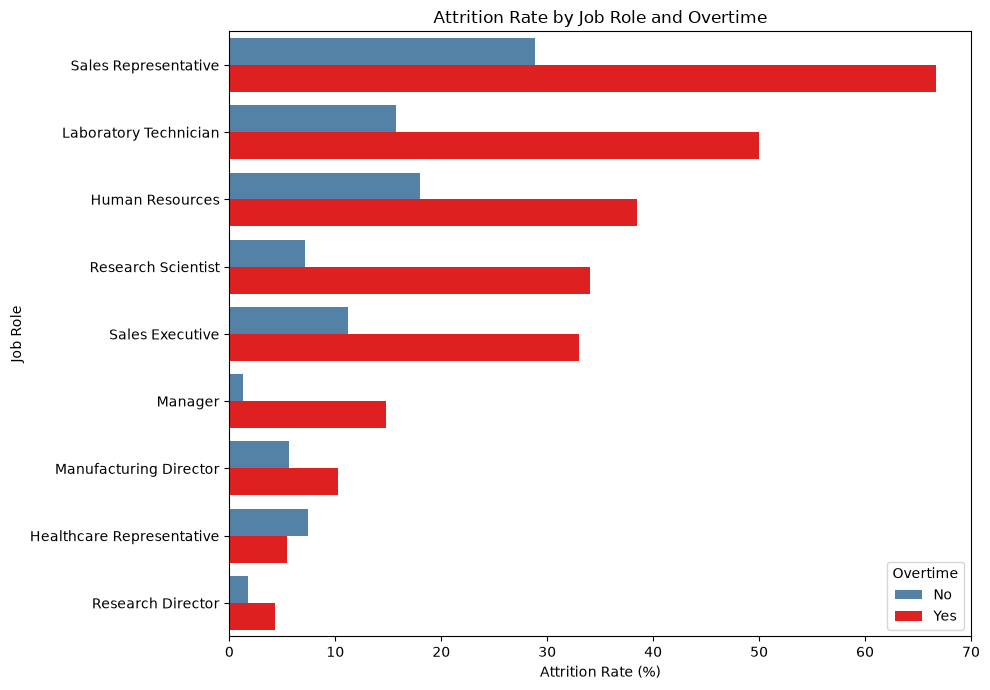

In [104]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=overtime_job_role,
    y="JobRole",
    x="AttritionRate",
    hue="OverTime",
    order=job_role_order,
    palette={
        "No": "steelblue",
        "Yes": "red",
    },
)

plt.title("Attrition Rate by Job Role and Overtime")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.legend(title="Overtime")

plt.tight_layout()
plt.show()

**Observation:** Overtime is associated with higher attrition across most job roles, but its impact varies considerably. Sales representatives show the highest attrition rate when working overtime, while laboratory technicians and research scientists also display substantial differences between the two overtime groups. Healthcare representatives are a notable exception, showing little difference in attrition based on overtime. This suggests that the relationship between overtime and employee turnover may depend partly on the demands of each job role.

### 4.3 Business Travel × Overtime

In [105]:
travel_overtime = (
    df.groupby(
        ["BusinessTravel", "OverTime"],
        observed=False,
    )
    .agg(
        Employees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda values: values.eq("Yes").sum()),
    )
    .reset_index()
)

travel_overtime["AttritionRate"] = (
    travel_overtime["EmployeesLeft"]
    .div(travel_overtime["Employees"])
    .mul(100)
    .round(2)
)

In [106]:
travel_without_overtime = (
    travel_overtime[
        travel_overtime["OverTime"] == "No"
    ]
    .drop(columns="OverTime")
    .sort_values("AttritionRate", ascending=False)
    .reset_index(drop=True)
)

travel_with_overtime = (
    travel_overtime[
        travel_overtime["OverTime"] == "Yes"
    ]
    .drop(columns="OverTime")
    .sort_values("AttritionRate", ascending=False)
    .reset_index(drop=True)
)

In [107]:
travel_overtime_comparison = pd.concat(
    {
        "Without Overtime": travel_without_overtime,
        "With Overtime": travel_with_overtime,
    },
    axis=1,
)

display(travel_overtime_comparison)

Without Overtime                                            With Overtime  \
      BusinessTravel Employees EmployeesLeft AttritionRate     BusinessTravel   
0  Travel_Frequently       191            33         17.28  Travel_Frequently   
1      Travel_Rarely       748            72          9.63      Travel_Rarely   
2         Non-Travel       115             5          4.35         Non-Travel   

                                         
  Employees EmployeesLeft AttritionRate  
0        86            36         41.86  
1       295            84         28.47  
2        35             7         20.00

In [108]:
travel_order = [
    "Non-Travel",
    "Travel_Rarely",
    "Travel_Frequently",
]

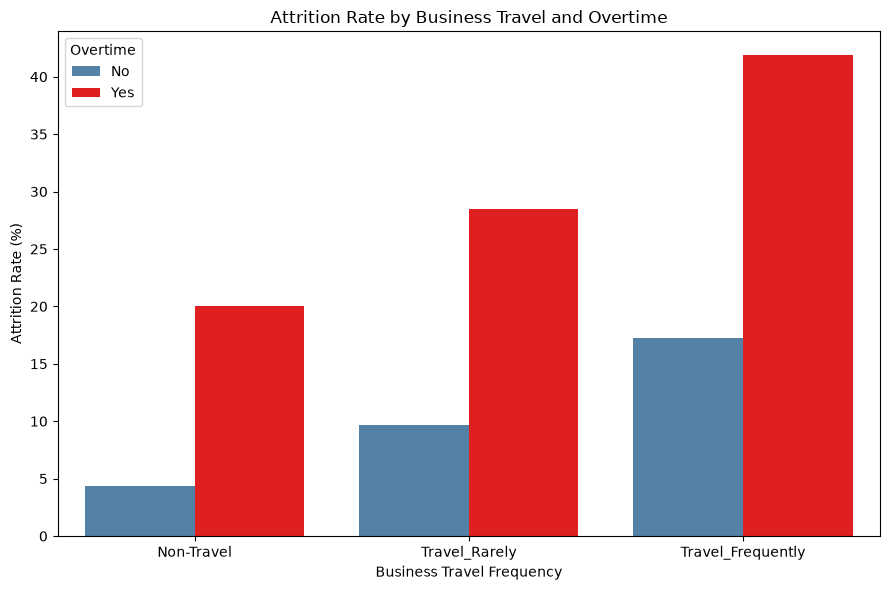

In [109]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=travel_overtime,
    x="BusinessTravel",
    y="AttritionRate",
    hue="OverTime",
    order=travel_order,
    palette={
        "No": "steelblue",
        "Yes": "red",
    },
)

plt.title("Attrition Rate by Business Travel and Overtime")
plt.xlabel("Business Travel Frequency")
plt.ylabel("Attrition Rate (%)")
plt.legend(title="Overtime")

plt.tight_layout()
plt.show()

**Observation:** Employees working overtime show considerably higher attrition across every business travel group. The combination of frequent business travel and overtime produces the highest turnover rate, suggesting that these two job demands may reinforce one another. Employees who do not travel and do not work overtime show the lowest attrition, indicating that lower work-related travel and time demands are associated with greater employee retention.

### 4.4 Job Level × Monthly Income

In [110]:
job_level_income = (
    df.groupby(
        ["JobLevel", "IncomeGroup"],
        observed=False,
    )
    .size()
    .reset_index(name="Employees")
)

In [111]:
job_level_income["Percentage"] = (
    job_level_income
    .groupby("JobLevel")["Employees"]
    .transform(lambda values: values.div(values.sum()).mul(100))
    .round(2)
)

In [112]:
job_level_income_counts = (
    job_level_income.pivot(
        index="JobLevel",
        columns="IncomeGroup",
        values="Employees",
    )
    .fillna(0)
    .astype(int)
)

job_level_income_percentages = (
    job_level_income.pivot(
        index="JobLevel",
        columns="IncomeGroup",
        values="Percentage",
    )
    .fillna(0)
)

In [113]:
job_level_income_comparison = pd.concat(
    {
        "Employee Counts": job_level_income_counts,
        "Percentages": job_level_income_percentages,
    },
    axis=1,
)

display(job_level_income_comparison)

Employee Counts                                                   \
IncomeGroup     12000–15999 16000+ 3000–4999 5000–7999 8000–11999 Under 3000   
JobLevel                                                                       
1                         0      0       162         0          0        381   
2                         0      0       192       294         34         14   
3                        23      0         0        46        149          0   
4                        46     57         0         0          3          0   
5                         0     69         0         0          0          0   

            Percentages                                                    
IncomeGroup 12000–15999  16000+ 3000–4999 5000–7999 8000–11999 Under 3000  
JobLevel                                                                   
1                  0.00    0.00     29.83      0.00       0.00      70.17  
2                  0.00    0.00     35.96     55.06       6.37       2.62  
3                 10.55    0.00      0.00     21.10      68.35       0.00  
4                 43.40   53.77      0.00      0.00       2.83       0.00  
5                  0.00  100.00      0.00      0.00       0.00       0.00

In [114]:
job_level_income_statistics = (
    df.groupby("JobLevel")["MonthlyIncome"]
    .agg(
        Employees="count",
        AverageIncome="mean",
        MedianIncome="median",
        MinimumIncome="min",
        MaximumIncome="max",
    )
    .round(2)
    .reset_index()
)

display(job_level_income_statistics)

,JobLevel,Employees,AverageIncome,MedianIncome,MinimumIncome,MaximumIncome
0,1,543,2786.92,2670.0,1009,4968
1,2,534,5502.28,5340.0,2042,9998
2,3,218,9817.25,9980.0,5210,13757
3,4,106,15503.78,16154.0,11103,17924
4,5,69,19191.83,19232.0,18041,19999


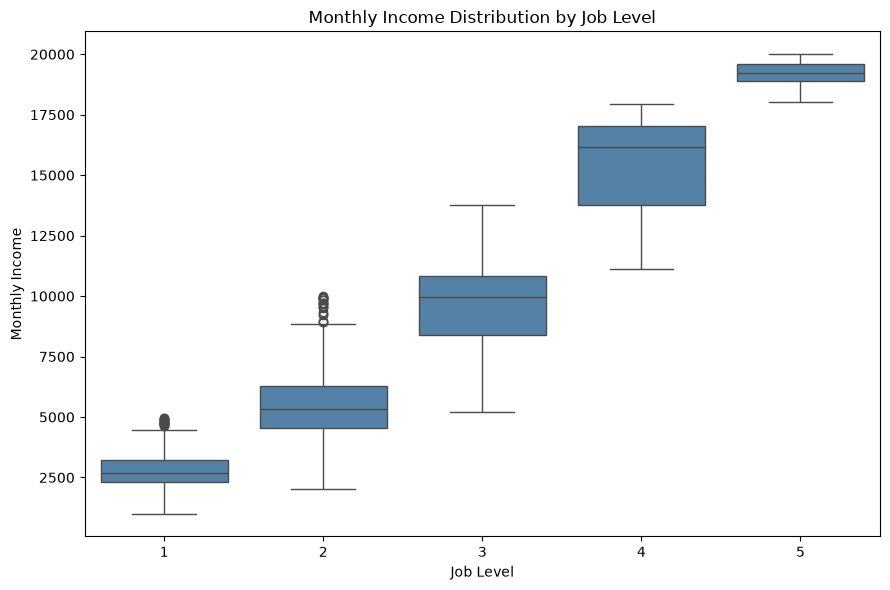

In [115]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="JobLevel",
    y="MonthlyIncome",
    color="steelblue",
)

plt.title("Monthly Income Distribution by Job Level")
plt.xlabel("Job Level")
plt.ylabel("Monthly Income")

plt.tight_layout()
plt.show()

**Observation:** Job level is a strong indicator of monthly income, with earnings increasing clearly at each successive level. Income ranges show relatively little overlap, particularly among the higher job levels, although some unusually high earners appear within lower levels. The mean and median incomes are also fairly close within each group, suggesting that extreme values do not substantially distort the typical salary at each job level.

### 4.5 Age × Total Working Years

In [116]:
age_working_years_correlation = df["Age"].corr(
    df["TotalWorkingYears"]
)

print(
    "Correlation between Age and Total Working Years: "
    f"{age_working_years_correlation:.2f}"
)

Correlation between Age and Total Working Years: 0.68


In [117]:
age_working_years_by_attrition = (
    df.groupby("Attrition")
    .agg(
        Employees=("Attrition", "size"),
        AverageAge=("Age", "mean"),
        MedianAge=("Age", "median"),
        AverageWorkingYears=("TotalWorkingYears", "mean"),
        MedianWorkingYears=("TotalWorkingYears", "median"),
    )
    .round(2)
    .reset_index()
)

display(age_working_years_by_attrition)

,Attrition,Employees,AverageAge,MedianAge,AverageWorkingYears,MedianWorkingYears
0,No,1233,37.56,36.0,11.86,10.0
1,Yes,237,33.61,32.0,8.24,7.0


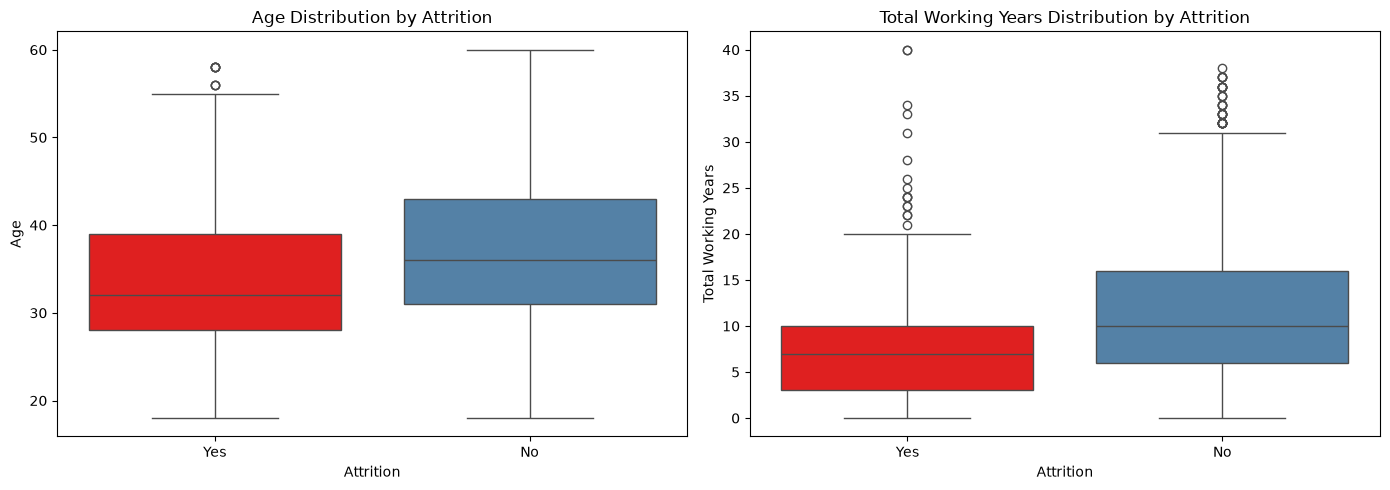

In [118]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

sns.boxplot(
    data=df,
    x="Attrition",
    y="Age",
    hue="Attrition",
    palette={
        "No": "steelblue",
        "Yes": "red",
    },
    legend=False,
    ax=axes[0],
)

axes[0].set_title("Age Distribution by Attrition")
axes[0].set_xlabel("Attrition")
axes[0].set_ylabel("Age")

sns.boxplot(
    data=df,
    x="Attrition",
    y="TotalWorkingYears",
    hue="Attrition",
    palette={
        "No": "steelblue",
        "Yes": "red",
    },
    legend=False,
    ax=axes[1],
)

axes[1].set_title("Total Working Years Distribution by Attrition")
axes[1].set_xlabel("Attrition")
axes[1].set_ylabel("Total Working Years")

plt.tight_layout()
plt.show()

**Observation:** Age and total working years show a moderate positive correlation, which is expected because older employees generally have more work experience. Employees who left IBM are, on average, approximately four years younger and have around three fewer total working years than those who stayed. This indicates that attrition is more concentrated among younger, less-experienced employees, although the overlapping distributions show that neither age nor experience independently determines employee turnover.

### 4.6 Department × Overtime

In [119]:
department_overtime = (
    df.groupby(
        ["Department", "OverTime"],
        observed=False,
    )
    .agg(
        Employees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda values: values.eq("Yes").sum()),
    )
    .reset_index()
)

department_overtime["AttritionRate"] = (
    department_overtime["EmployeesLeft"]
    .div(department_overtime["Employees"])
    .mul(100)
    .round(2)
)

In [120]:
department_order = [
    "Human Resources",
    "Research & Development",
    "Sales",
]

In [121]:
department_without_overtime = (
    department_overtime[
        department_overtime["OverTime"] == "No"
    ]
    .drop(columns="OverTime")
    .set_index("Department")
    .reindex(department_order)
    .reset_index()
)

department_with_overtime = (
    department_overtime[
        department_overtime["OverTime"] == "Yes"
    ]
    .drop(columns="OverTime")
    .set_index("Department")
    .reindex(department_order)
    .reset_index()
)

In [122]:
department_overtime_comparison = pd.concat(
    {
        "Without Overtime": department_without_overtime,
        "With Overtime": department_with_overtime,
    },
    axis=1,
)

display(department_overtime_comparison)

Without Overtime                                        \
               Department Employees EmployeesLeft AttritionRate   
0         Human Resources        46             7         15.22   
1  Research & Development       690            59          8.55   
2                   Sales       318            44         13.84   

            With Overtime                                        
               Department Employees EmployeesLeft AttritionRate  
0         Human Resources        17             5         29.41  
1  Research & Development       271            74         27.31  
2                   Sales       128            48         37.50

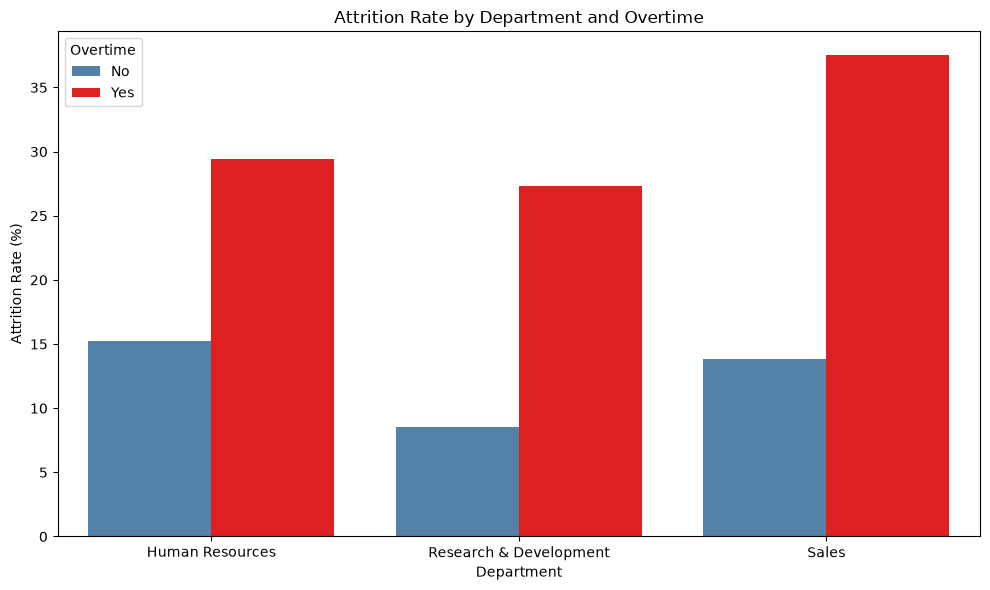

In [123]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_overtime,
    x="Department",
    y="AttritionRate",
    hue="OverTime",
    order=department_order,
    palette={
        "No": "steelblue",
        "Yes": "red",
    },
)

plt.title("Attrition Rate by Department and Overtime")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.legend(title="Overtime")

plt.tight_layout()
plt.show()

**Observation:** Overtime is associated with substantially higher attrition across all three departments. Sales shows the largest difference between employees with and without overtime, followed by Research & Development. Human Resources also displays elevated attrition among employees working overtime, but its smaller employee sample means that this result should be interpreted cautiously. Overall, overtime appears to be an important attrition factor across the organization rather than an issue limited to one department.

### 4.7 Marital Status × Overtime

In [124]:
marital_overtime = (
    df.groupby(
        ["MaritalStatus", "OverTime"],
        observed=False,
    )
    .agg(
        Employees=("Attrition", "size"),
        EmployeesLeft=("Attrition", lambda values: values.eq("Yes").sum()),
    )
    .reset_index()
)

marital_overtime["AttritionRate"] = (
    marital_overtime["EmployeesLeft"]
    .div(marital_overtime["Employees"])
    .mul(100)
    .round(2)
)

In [125]:
marital_status_order = [
    "Single",
    "Married",
    "Divorced",
]

In [126]:
marital_without_overtime = (
    marital_overtime[
        marital_overtime["OverTime"] == "No"
    ]
    .drop(columns="OverTime")
    .set_index("MaritalStatus")
    .reindex(marital_status_order)
    .reset_index()
)

marital_with_overtime = (
    marital_overtime[
        marital_overtime["OverTime"] == "Yes"
    ]
    .drop(columns="OverTime")
    .set_index("MaritalStatus")
    .reindex(marital_status_order)
    .reset_index()
)

In [127]:
marital_overtime_comparison = pd.concat(
    {
        "Without Overtime": marital_without_overtime,
        "With Overtime": marital_with_overtime,
    },
    axis=1,
)

display(marital_overtime_comparison)

Without Overtime                                       With Overtime  \
     MaritalStatus Employees EmployeesLeft AttritionRate MaritalStatus   
0           Single       339            55         16.22        Single   
1          Married       487            41          8.42       Married   
2         Divorced       228            14          6.14      Divorced   

                                         
  Employees EmployeesLeft AttritionRate  
0       131            65         49.62  
1       186            43         23.12  
2        99            19         19.19

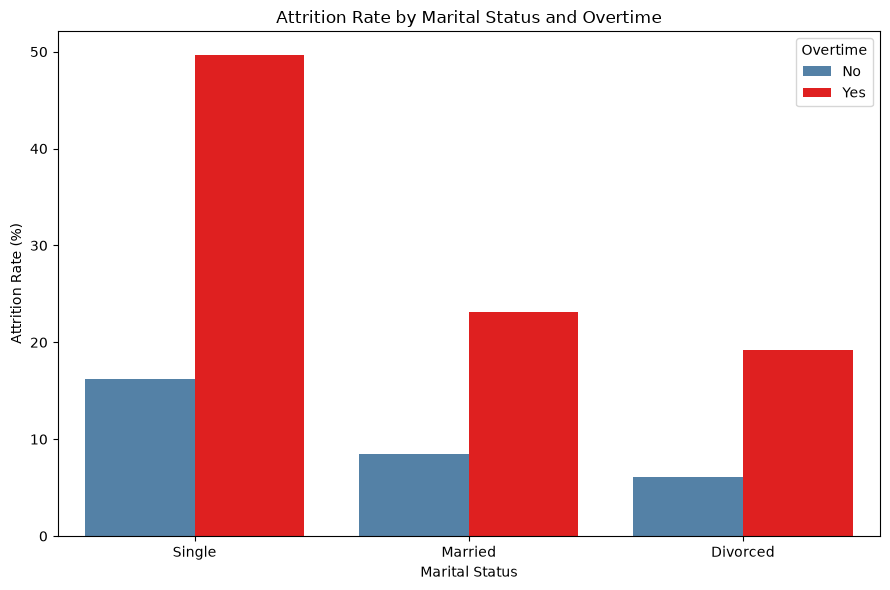

In [128]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=marital_overtime,
    x="MaritalStatus",
    y="AttritionRate",
    hue="OverTime",
    order=marital_status_order,
    palette={
        "No": "steelblue",
        "Yes": "red",
    },
)

plt.title("Attrition Rate by Marital Status and Overtime")
plt.xlabel("Marital Status")
plt.ylabel("Attrition Rate (%)")
plt.legend(title="Overtime")

plt.tight_layout()
plt.show()

**Observation:** Overtime is associated with substantially higher attrition across every marital-status group. Single employees working overtime show the highest turnover rate at approximately 50%, making this the most notable combination. Married and divorced employees also experience increased attrition when working overtime, although their rates remain lower than those of single employees. This suggests that overtime is an important attrition factor regardless of marital status, with single employees appearing particularly vulnerable.